# Task 5: Titanic Survival Classification

## Barakah TechLabs – Applied Data Scientist Internship

This project focuses on predicting passenger survival using the Titanic dataset.

The classification models used in this project are:

- Logistic Regression
- Decision Tree Classifier

The models will be evaluated using classification metrics and confusion matrices.

## Import Required Libraries

The required Python libraries are imported for data analysis, visualization, preprocessing, model training, and evaluation.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Dataset Loading

The Titanic dataset is loaded using the Seaborn library.

In [28]:
# Load Titanic dataset
df = sns.load_dataset("titanic")

# Display first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Exploratory Data Analysis

The dataset structure, dimensions, data types, and statistical characteristics are examined to understand the data before model development.

In [29]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

Dataset Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [30]:
# Statistical summary
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Missing Value Analysis

The dataset is checked for missing values to identify columns that require preprocessing before training the machine learning models.

In [31]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values)

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


## Survival Distribution

The distribution of the target variable, Survival, is visualized to understand the number of passengers who survived and did not survive.

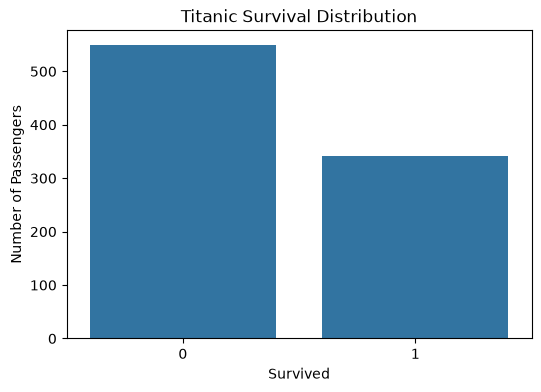

In [32]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

## Class Imbalance Analysis

The distribution of the survival classes is analyzed to determine whether there is an imbalance between passengers who survived and those who did not survive.

In [33]:
class_distribution = df["survived"].value_counts()

print(class_distribution)

print("\nClass Percentage:")
print(df["survived"].value_counts(normalize=True) * 100)

survived
0    549
1    342
Name: count, dtype: int64

Class Percentage:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


## Survival by Gender

The relationship between passenger gender and survival is visualized to explore differences in survival outcomes.

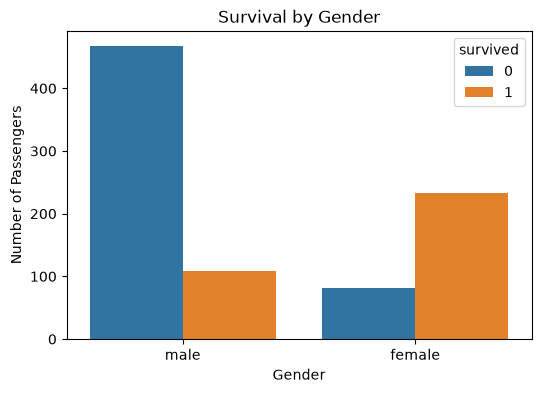

In [34]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

## Survival by Passenger Class

The relationship between passenger class and survival is visualized to examine survival patterns across different passenger classes.

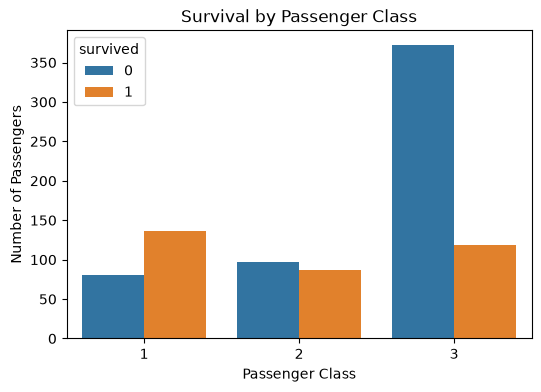

In [35]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="pclass", hue="survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

## Feature Selection

Relevant passenger attributes are selected as input features for the classification models.

The target variable is `survived`.

In [36]:
# Select relevant features
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features].copy()
y = df["survived"].copy()

X.head()

,pclass,sex,age,sibsp,parch,fare,embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


## Handling Missing Values

Missing numerical values are filled using the median, while missing categorical values are filled using the most frequent category.

In [37]:
# Fill missing numerical values
X["age"] = X["age"].fillna(X["age"].median())
X["fare"] = X["fare"].fillna(X["fare"].median())

# Fill missing categorical values
X["embarked"] = X["embarked"].fillna(X["embarked"].mode()[0])

# Check remaining missing values
print(X.isnull().sum())

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


## Encoding Categorical Variables

Categorical variables are converted into numerical features using one-hot encoding so that they can be used by the machine learning models.

In [38]:
# Convert categorical variables into numerical columns
X = pd.get_dummies(
    X,
    columns=["sex", "embarked"],
    drop_first=True
)

# Convert boolean columns to integers
X = X.astype(int)

X.head()

,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,3,22,1,0,7,1,0,1
1,1,38,1,0,71,0,0,0
2,3,26,0,0,7,0,0,1
3,1,35,1,0,53,0,0,1
4,3,35,0,0,8,1,0,1


## Train-Test Split

The dataset is divided into training and testing sets.

Stratification is used to maintain a similar distribution of the survival classes in both datasets.

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 712
Testing samples: 179


## Feature Scaling

Feature scaling is applied before Logistic Regression so that numerical features are placed on a comparable scale.

In [40]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Logistic Regression

Logistic Regression is used as the first classification model to predict whether a passenger survived.

Balanced class weights are used to account for the difference between the survival classes.

In [41]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

## Decision Tree Classifier

A Decision Tree Classifier is used as the second classification model for predicting passenger survival.

Balanced class weights are used to account for the class distribution.

In [42]:
decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42,
    max_depth=5
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_test)

## Model Evaluation

Both classification models are evaluated using the following metrics:

- Accuracy
- Precision
- Recall
- F1-Score

In [43]:
# Logistic Regression metrics
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)
logistic_recall = recall_score(y_test, logistic_predictions)
logistic_f1 = f1_score(y_test, logistic_predictions)

# Decision Tree metrics
tree_accuracy = accuracy_score(y_test, decision_tree_predictions)
tree_precision = precision_score(y_test, decision_tree_predictions)
tree_recall = recall_score(y_test, decision_tree_predictions)
tree_f1 = f1_score(y_test, decision_tree_predictions)

# Results table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy],
    "Precision": [logistic_precision, tree_precision],
    "Recall": [logistic_recall, tree_recall],
    "F1-Score": [logistic_f1, tree_f1]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.804469,0.729730,0.782609,0.755245
1,Decision Tree,0.776536,0.693333,0.753623,0.722222


## Classification Reports

Detailed classification reports are generated for both Logistic Regression and Decision Tree Classifier to examine their classification performance.

In [44]:
print("Logistic Regression Classification Report")
print(classification_report(y_test, logistic_predictions))

print("\nDecision Tree Classification Report")
print(classification_report(y_test, decision_tree_predictions))

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.86      0.82      0.84       110
           1       0.73      0.78      0.76        69

    accuracy                           0.80       179
   macro avg       0.79      0.80      0.80       179
weighted avg       0.81      0.80      0.81       179


Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.84      0.79      0.81       110
           1       0.69      0.75      0.72        69

    accuracy                           0.78       179
   macro avg       0.76      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



## Confusion Matrices

Confusion matrices are used to visualize correct and incorrect predictions made by the classification models.

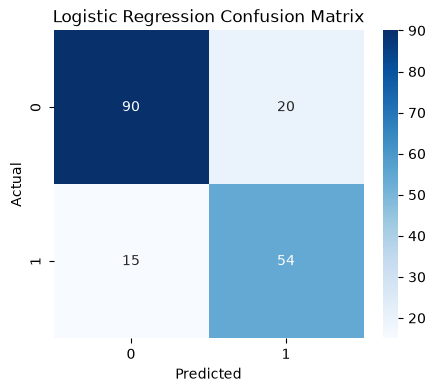

In [45]:
# Logistic Regression confusion matrix
logistic_cm = confusion_matrix(y_test, logistic_predictions)

plt.figure(figsize=(5, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## Model Performance Comparison

The performance of Logistic Regression and Decision Tree Classifier is compared using the selected evaluation metrics.

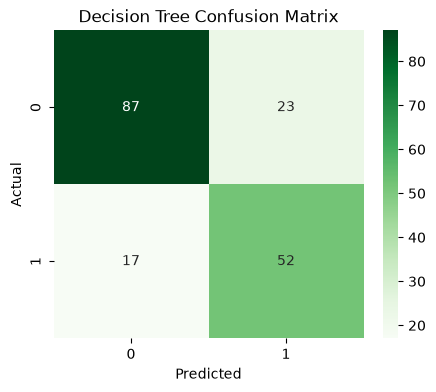

In [46]:
tree_cm = confusion_matrix(y_test, decision_tree_predictions)

plt.figure(figsize=(5, 4))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

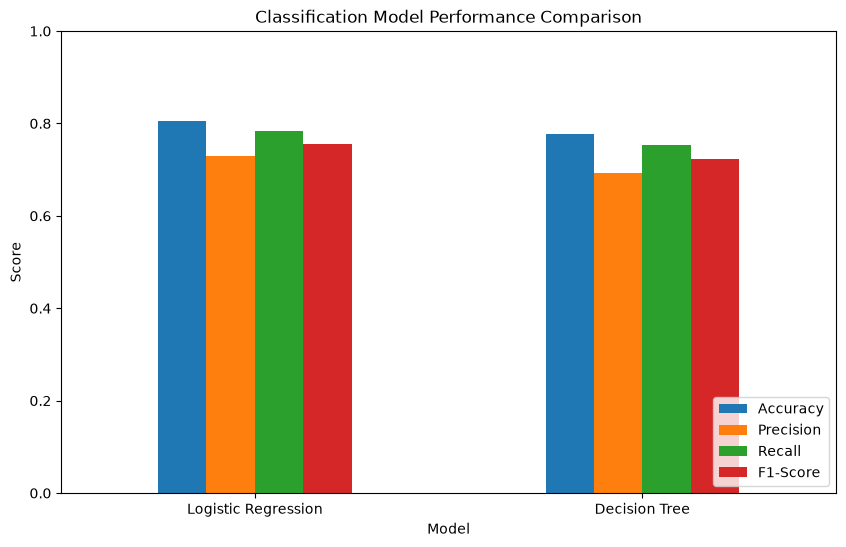

In [47]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.show()

## Feature Importance

The Decision Tree model provides feature importance values that show the relative contribution of each feature to the model's predictions.

In [48]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": decision_tree_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
5,sex_male,0.550172
0,pclass,0.160926
1,age,0.147296
4,fare,0.113998
7,embarked_S,0.016960
2,sibsp,0.007797
3,parch,0.002850
6,embarked_Q,0.000000


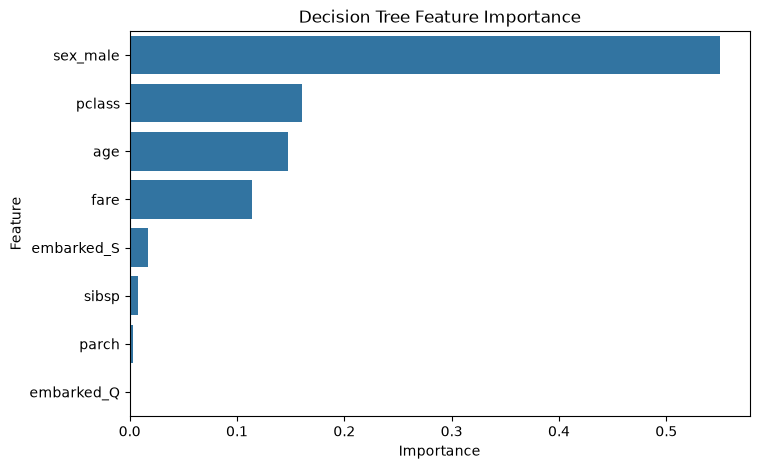

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

# Conclusion

In this project, Titanic passenger survival was predicted using two classification algorithms:

- Logistic Regression
- Decision Tree Classifier

The dataset was explored for missing values and class distribution before model development. Missing values were handled, categorical variables were encoded, and the data was divided into training and testing sets using stratification.

Class weights were used in both models to account for the imbalance between the survival classes.

The models were evaluated using Accuracy, Precision, Recall, and F1-Score.

### Model Performance

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.8045 | 0.7297 | 0.7826 | 0.7552 |
| Decision Tree | 0.7765 | 0.6933 | 0.7536 | 0.7222 |

On the test dataset, Logistic Regression achieved higher Accuracy, Precision, Recall, and F1-Score than the Decision Tree Classifier.

Overall, this project demonstrates a complete classification workflow including exploratory data analysis, missing value handling, class imbalance analysis, feature preprocessing, model training, evaluation, and visualization.

## Project Summary

This project demonstrates a complete machine learning classification workflow, including:

- Exploratory Data Analysis
- Missing Value Handling
- Class Imbalance Analysis
- Feature Selection
- Categorical Encoding
- Train-Test Split
- Feature Scaling
- Logistic Regression
- Decision Tree Classification
- Model Evaluation
- Confusion Matrix Analysis
- Model Comparison
- Feature Importance Analysis

In [50]:
results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8045,0.7297,0.7826,0.7552
1,Decision Tree,0.7765,0.6933,0.7536,0.7222
